# Dataset Audit

This notebook contains a thorough dataset audit of the chosen dataset, the Brown Corpus,
for the purposes of this project.

Jupyter notebook is the chosen format for this audit, as it's much simpler to see and visualise
both the commands, i.e. what's actually happening, as well as their results and accompanying text descriptions.

Functional pieces of code remain in their respective Python modules (`*.py` files in the current directory),
and are imported here when necessary.

## Running the code

To ensure all code in this Jupyter notebook can run, make sure to use a Kernel associated with a virtual environment
set up for the `dataset` directory, which can be done using the following shell commands:

```bash
# Set up virtual environment
python -m venv venv

# Install required packages
pip install -r requirements.txt

# Set up kernel
python -m ipykernel install --user --name=<Jupyter_Kernel_Name>
```

After this, the kernel can be selected in the user's running Jupyter instance.


## Loading the dataset

The module `dataset_loader.py` provides convenience functions to import datasets from Kaggle,
which is the selected data source for this project.

Using the functions may require Kaggle authentication.

In [12]:
import dataset_loader
df = dataset_loader.load_brown_corpus_df()

The following cell shows the basic, unprocessed and summarised view of the loaded dataframe.

In [14]:
df

,filename,para_id,sent_id,raw_text,tokenized_text,tokenized_pos,label
0,cd05,0,0,"Furthermore/rb ,/, as/cs an/at encouragement/n...","Furthermore , as an encouragement to revisioni...","rb , cs at nn in nn nn , pps rb bez jj to vb c...",religion
1,cd05,0,1,The/at Unitarian/jj clergy/nns were/bed an/at ...,The Unitarian clergy were an exclusive club of...,at jj nns bed at jj nn in vbn nns -- cs at nn ...,religion
2,cd05,0,2,"Ezra/np Stiles/np Gannett/np ,/, an/at honorab...","Ezra Stiles Gannett , an honorable representat...","np np np , at jj nn in at nn , vbd ppl rb in a...",religion
3,cd05,0,3,"Even/rb so/rb ,/, Gannett/np judiciously/rb ar...","Even so , Gannett judiciously argued , the Ass...","rb rb , np rb vbd , at nn-tl md rb vb cs np ``...",religion
4,cd05,0,4,We/ppss today/nr are/ber not/* entitled/vbn to...,We today are not entitled to excoriate honest ...,ppss nr ber * vbn to vb jj nns wps vbd np to b...,religion
...,...,...,...,...,...,...,...
57335,cj14,6,3,"For/in the/at most/ap part/nn ,/, this/dt disc...","For the most part , this discussion will be co...","in at ap nn , dt nn md be vbn in nns vbn in at...",learned
57336,cj14,6,4,A/np-hl ./.-hl,A .,np-hl .-hl,learned
57337,cj14,6,5,Standard/jj-hl preparations/nns-hl and/cc-hl u...,Standard preparations and units of thyroid-sti...,jj-hl nns-hl cc-hl nns-hl in-hl jj-hl nn-hl,learned
57338,cj14,6,6,The/at international/jj unit/nn (/( u./nn )/) ...,"The international unit ( u. ) , adopted to mak...","at jj nn ( nn ) , vbn to vb jj at nn in nns in...",learned


## Dataset Shape, Strata and Variables

Based on the summarised raw dataframe shape, there are a few areas we can highlight that should be focused on in the dataset audit.

### Shape

Firstly, we can check the overall number of rows and columns, which is the basic dataset shape.
This can be done using `df.shape`.

In [15]:
df.shape

(57340, 7)

There are 57,340 total rows in the dataset, which also means 57,340 total entries.
The number of columns is not as significant, as the column `raw_text` contains all features necessary for the model.

### Strata

Next, looking at the `label` column, we can see that not all entries have the same genre of content.
Since the genre of text content has an impact on the accuracy of part-of-speech tagging 
(which is why language corpora typically have many genres represented),
we need to ensure the `label` is properly accounted for when splitting data.

Using a Python Set, we can find the unique label names and the number of unique labels in the dataset.

In [23]:
unique_labels = set(df["label"])
print(f"Unique labels: \n- {"\n- ".join(unique_labels)}\n")
print(f"Number of unique labels: {len(unique_labels)}")

Unique labels: 
- adventure
- mystery
- news
- learned
- editorial
- romance
- fiction
- reviews
- belles_lettres
- humor
- lore
- government
- hobbies
- religion
- science_fiction

Number of unique labels: 15


Next, we can look at the distribution of entries per label.
The distribution can be visualised as a bar chart using MatPlotLib.

In [53]:
entry_by_label = {label: len(df.loc[df["label"] == label]) for label in unique_labels}
entry_by_label

{'adventure': 4637,
 'mystery': 3886,
 'news': 4623,
 'learned': 7734,
 'editorial': 2997,
 'romance': 4431,
 'fiction': 4249,
 'reviews': 1751,
 'belles_lettres': 7209,
 'humor': 1053,
 'lore': 4881,
 'government': 3032,
 'hobbies': 4193,
 'religion': 1716,
 'science_fiction': 948}

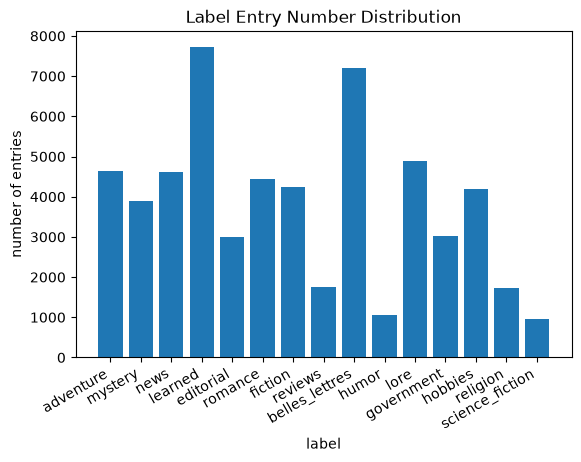

In [54]:
import matplotlib.pyplot as plt
plt.bar(entry_by_label.keys(), entry_by_label.values())
plt.title("Label Entry Number Distribution")
plt.xlabel("label")
plt.ylabel("number of entries")
plt.gca().get_figure().autofmt_xdate() # Automatically format x-tick labels to not clash
plt.show()

The uneven per-label entry count distribution, combined with the fact that each label contains entries
with equally important data and that there is no correlation between entries in different labels,
supports using a stratified approach to the split.

When splitting the dataset into a train, validation and test components, the dataset audit backs
the use of a stratified split, i.e. rather than the train percentage taken at random from the entire dataset,
the corresponding percentages will be selected from entries under each label and merged.

This ensures even data distribution in all parts of the dataset.

### Variables

The target variable is the part-of-speech tag for each specific word in a given sequence of text.
The dataset provides 3 columns, one with the raw text consisting of sentences with each word's POS tag attached,
then another one with just the words without the tags, and a third one with just the corresponding tags.

As per the Brown Corpus Manual (Francis and Kucera, 1979), there are 82 unique part-of-speech tags in the dataset.
First, we should quantify whether this matches our downloaded data or whether any outliers are present.
It's useful to both look at all the present POS tags as well as the numbers of each type,
which also provides a base target variable distribution.

In [106]:
pos_tags = set(tag for entry in df["tokenized_pos"] for tag in entry.split())
print("Unique POS tags:", len(pos_tags))

pos_tag_counts = {x: 0 for x in pos_tags}
for entry in df["tokenized_pos"]:
    for tag in entry.split():
        pos_tag_counts[tag] += 1

# Some potential outlier tags - only one occurence in entire dataset
print([x for x in pos_tag_counts if pos_tag_counts[x] == 1])

Unique POS tags: 523
['fw-jjt', 'ft', 'fw-ppss+hv', 'wdt+bez-hl', 'jj-tl-nc', 'ppl-tl', '1', 'ppss+ber-n', 'jjs-hl', 'fw-uh-nc', 'vb+vb-nc', 'ber*-nc', 'chamber', 'pn+hvd', 'wrb+doz', 'wrb+dod*', '20th', 'ppss+hv-tl', 'wrb+in', 'dod-nc', '4-inch', 'fw-uh-tl', 'fw-pn', 'nns$-tl-hl', 'fw-jjr', '*-nc', 'ppss+bez', 'fw-vbd-tl', 'fw-nn-tl-nc', 'fw-nr', '29', 'nn+hvd-tl', 'fw-wpo', 'be-tl', 'g', 'jjr+cs', 'wdt+ber+pp', 'hvd-hl', 'abn-nc', 'fw-to+vb', 'fw-rb+cc', 'wrb+md', 'nps$-hl', 'ppss+ber-nc', 'destination', 'ap+ap-nc', 'fw-dts', 'ex-hl', 'wps+bez-tl', 'fw-vb-tl', 'ex-nc', 'wrb+ber', 'doz*-tl', 'hp', 'np+hvz-nc', 'ppss+ber-tl', '2-foot', 'rb+bez-nc', 'sq.', 'in+in', 'lBOD', 'nn+hvz-tl', '3%', 'active', 'nn+in', 'cell', 'nn+nn-nc', 'dod*-tl', 'r', 'md+ppss', '8-inch-thick', 'ppss+bez*', 'nrs-tl', 'cwt', 'hvg-hl', 'coating', 'rbr+cs', 'wpo-nc', 'jj$-tl', 'bedz-hl', 'vb+jj-nc', 'wrb+do', '9', 'uh-hl', 'wdt+bez-tl', 'wdt+ber', 'jjt-nc', 'rbr-nc', '7', 'fw-pp$-nc', 'fw-od-nc', 'do+ppss', 'fw-

This result shows that the Kaggle-provided dataset doesn't precisely match the corpus as described in the manual.

By looking at some of the rarest of the 523 total tags that exist in the Kaggle-processed tokenised POS entries,
we can see 2 patterns emerge that will impact our data pre-processing strategy.

```
# TODO Issue: Splitting of some of the data done wrong for the Kaggle tokenised entries
# For example, 1/4-inch/nn gets parsed into word '1' and POS tag '4-inch'
# TODO Show methodology of finding this, correct by doing own data processing
```

TODO Here:
- Evaluate and process the target variables
- Basically visualise and propose a strategy based on the visualisation about how to process the various POS tags
- Reference the corpus manual for POS tag names etc.

### TODO
- Missing Values (check each row for a non-zero entry tokenized, as well as each word has an adequate tag)
- Duplicates (check for fully equal tokenized text, then mention whether same POS tags as well or not)
- Target Distribution (how many of each part of speech there are)
- Outliers (entries with too many or too few words, entries with only one or two unique POS tags)

After this is done, add a conclusion which will inform the actual processing pipeline.

Processing pipeline - functor-style class or set of functions in a module, for reproducibility,
which will run and export data into a format usable by the 'models' section, so far with just the baseline model.